<div style="padding:28px 32px;border-radius:16px;background:linear-gradient(120deg,#143454,#147d85);color:white">
<div style="font-size:13px;letter-spacing:3px">AI401 · ADVANCED COMPUTER VISION</div>
<h1 style="color:white;margin:12px 0">Part 3 · DINOv3 + MAE</h1>
<p style="font-size:18px;margin:0">Transfer, feature distortion & soil-domain adaptation</p>
</div>

**One physical scale · four fixed sample folds · two SSL encoders · eighteen recipes.**

We compare frozen k-NN/ridge → linear probe → LP-FT → full fine-tuning, then repeat
all five strategies after fold-local DINO-style adaptation. Every result comes
from saved OOF curves. See [SSL_README.md](SSL_README.md) for the protocol.

## 1 · Before running

Attach the competition, the latest `soil-cv-utils` and private
`soil-ssl-official-weights`. Select **2 × T4 + Internet**, and enable the existing
`WANDB_API_KEY` secret. `SMOKE=True` performs a short integration check without
W&B and never reports it as a complete study.

Hypotheses were written in `HYPOTHESES.md` before runs. No commits are made,
as requested by the project owner. Hyperparameters and exact Hub revisions are
saved alongside the results.

**Fresh logging revision:** stop the previous session first. Outputs use the new
`part3_ssl_v2` folder. Each recipe/fold is a separate W&B run with the same
`train/*`, `val/*`, `best/*` and `epoch` names as Parts 1–2.


In [1]:
SMOKE = False

import json
import os
import shutil
import subprocess
import sys
import time
allocation_started = time.perf_counter()
from pathlib import Path

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'transformers==4.57.1', 'wandb>=0.25.1'])
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['WANDB_CACHE_DIR'] = '/tmp/soilcv-ssl-wandb'
os.environ['SOILCV_SSL_OUTPUT_DIR'] = '/kaggle/working/part3_ssl_v2'
code_roots = [p.parents[2] for p in Path('/kaggle/input').rglob('soilcv/ssl/model.py')]
if len(code_roots) != 1:
    raise RuntimeError('Attach exactly one current soil-cv-utils dataset.')
code_root = code_roots[0]
sys.path.insert(0, str(code_root))
os.environ['PYTHONPATH'] = str(code_root) + os.pathsep + os.environ.get('PYTHONPATH', '')
weights = [p.parent for p in Path('/kaggle/input').rglob('dinov3/config.json')
           if (p.parent.parent / 'mae/model.safetensors').is_file()]
if len(weights) != 1:
    raise RuntimeError('Attach the private official DINOv3 + MAE weights dataset.')
os.environ['SOILCV_SSL_MODELS'] = str(weights[0].parent)

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from soilcv.artifacts import package_identity

EXPECTED_SOURCE_HASH = '7fb12eaa31b8d2e189265fe58b5805379d2a3b742dcfeb00df70f77dd3adffdb'
if package_identity()['source_hash'] != EXPECTED_SOURCE_HASH:
    raise RuntimeError('Code differs from this notebook: attach the matching dataset version.')
if torch.cuda.device_count() != 2:
    raise RuntimeError('Select 2 × T4 GPUs.')
if not SMOKE:
    from kaggle_secrets import UserSecretsClient
    os.environ['WANDB_API_KEY'] = UserSecretsClient().get_secret('WANDB_API_KEY')
print('GPUs:', [torch.cuda.get_device_name(i) for i in range(2)])
print('Source:', package_identity())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


GPUs: ['Tesla T4', 'Tesla T4']
Source: {'version': '0.1.1', 'source_hash': '7fb12eaa31b8d2e189265fe58b5805379d2a3b742dcfeb00df70f77dd3adffdb', 'folds_hash': '057fe8f93ba35d2ab7a3483063c95ca0079c4bcbb9978671c16ffc4119d9c1b2'}


## 2 · The experiment matrix

DINOv3-S/16 and MAE-B/16 use **CLS + mean patch features**. Registers are excluded;
MAE masks no patches and keeps deterministic raster order. The models differ in
size, so this comparison does not isolate the SSL objective.

Ridge fits its scaler on training soils only. LP learns eleven mass logits, then
softmax + cumulative sum gives a valid curve. LP-FT initializes from LP; full FT
uses a fresh head. Only validation EMD selects the best epoch.

In [2]:
from soilcv.ssl.experiments import ROOT, CACHE, SETTINGS, prepare
from soilcv.ssl.analysis import expected_experiments, save_source

matrix = pd.DataFrame([{'experiment': key, 'encoder': value[0], 'source': value[1],
                        'strategy': value[2]} for key, value in expected_experiments().items()])
display(matrix)
print(json.dumps(SETTINGS, indent=2))

,experiment,encoder,source,strategy
0,dinov3-knn,dinov3,dinov3,knn
1,dinov3-ridge,dinov3,dinov3,ridge
2,dinov3-lp,dinov3,dinov3,lp
3,dinov3-lpft,dinov3,dinov3,lpft
4,dinov3-full,dinov3,dinov3,full
5,mae-knn,mae,mae,knn
6,mae-ridge,mae,mae,ridge
7,mae-lp,mae,mae,lp
8,mae-lpft,mae,mae,lpft
9,mae-full,mae,mae,full


{
  "preprocessing": {
    "tile_mm": 64,
    "pixels": 224,
    "interpolation": "LANCZOS",
    "normalization": {
      "mean": [
        0.485,
        0.456,
        0.406
      ],
      "std": [
        0.229,
        0.224,
        0.225
      ]
    },
    "pooling": "overlap_area_then_equal_photos",
    "random_resized_crop": false
  },
  "encoders": {
    "dinov3": {
      "repo": "facebook/dinov3-vits16-pretrain-lvd1689m",
      "revision": "114c1379950215c8b35dfcd4e90a5c251dde0d32"
    },
    "mae": {
      "repo": "facebook/vit-mae-base",
      "revision": "25b184bea5538bf5c4c852c79d221195fdd2778d"
    }
  },
  "strategies": [
    "knn",
    "ridge",
    "lp",
    "lpft",
    "full"
  ],
  "lp_epochs": 100,
  "lp_patience": 15,
  "ft_epochs": 16,
  "ft_patience": 5,
  "head_lr": 0.001,
  "backbone_lr": 1e-05,
  "weight_decay": 0.05,
  "layer_decay": 0.75,
  "warmup": 2,
  "adaptation": {
    "epochs": 10,
    "batch_size": 32,
    "backbone_lr": 1e-05,
    "head_lr": 0.0001,

## 3 · Fixed millimetres, complete coverage

All native 64 mm crops are resized **directly to 224 px**. Overlap-corrected tile
areas sum to one per photo; photos have equal sample weight. One soil gives one
EMD loss. Quarter-turns and flips preserve scale; color jitter is mild.
Random zoom, resized crops, strong blur and mixed-image targets are excluded.

No foreground mask or calibrated overlap between different photos is assumed.
PPM retains the original full-image-resize assumption.

In [3]:
prepare()
save_source(ROOT)
coverage = pd.read_csv(ROOT / 'coverage.csv')
display(coverage.groupby('device').agg(photos=('photo', 'size'), tiles=('tiles', 'sum'),
                                     min_coverage=('coverage', 'min')))
assert coverage.coverage.eq(1).all()

Prepared 3646 physical tiles; 24 labelled soils


,photos,tiles,min_coverage
device,,,
Motorola Edge,69,1242,1.0
Motorola Edge 60 Fusion,3,54,1.0
Samsung A52,55,1650,1.0
iPhone 14,14,280,1.0
iPhone 16,21,420,1.0


## 4 · Train & adapt

Eight independent encoder/fold workers run two at a time. DINOv3 adaptation sees
only the training soils of its fold: **no validation or test photos**. The EMA
teacher uses centering and sharpening; two full-tile views preserve scale. Ten
fixed epochs select the final teacher without validation labels. This is a small
DINO-style continuation, not full DINOv3 pretraining.

A short smoke run uses fewer soils/epochs and saves into a separate directory.

W&B groups by the recipe (`config.experiment_id`), e.g. `dinov3-lpft` or
`mae-full`. Each run starts at epoch zero. Adaptation has its own
`dinov3-adaptation` group and `adaptation/*` loss.


In [4]:
if SMOKE:
    from soilcv.ssl import experiments as study
    from soilcv.ssl.adaptation import ADAPTATION, adapt_encoder
    from soilcv.ssl.data import adaptation_loader
    from soilcv.ssl.model import SSLEncoder
    from soilcv.ssl.inference import predict_fold
    import numpy as np

    for key in ['lp_epochs', 'ft_epochs']:
        study.SETTINGS[key] = 2
    metadata = json.loads((ROOT / 'metadata.json').read_text())
    manifest = pd.read_json(ROOT / 'tiles.json')
    labels = pd.read_json(ROOT / 'labels.json')
    folds = pd.read_csv(ROOT / 'sample_folds.csv')
    selected = ([folds.loc[folds.fold.eq(0), 'sample_id'].iloc[0]]
                + folds.loc[folds.fold.ne(0), 'sample_id'].head(3).tolist())
    test_id = manifest.loc[manifest.fold.isna(), 'sample_id'].iloc[0]
    subset = manifest[manifest.sample_id.isin(selected + [test_id])]
    selected_folds = folds[folds.sample_id.isin(selected)]
    for name in ['dinov3', 'mae']:
        encoder = SSLEncoder(name, source=metadata['models'][name]['path']).to('cuda:0')
        folder = ROOT.parent / 'part3_smoke' / name
        study.run_source(name, 'smoke-' + name, encoder, subset, labels,
                         selected_folds, 0, folder, metadata, 'cuda:0', None)
        photos = pd.read_json(ROOT / 'photos.json')
        reload = predict_fold(folder / 'lpft', photos[photos.sample_id.eq(test_id)],
                              CACHE, device='cuda:0', amp=True)
        saved = pd.read_csv(folder / 'lpft/test_predictions.csv')
        np.testing.assert_allclose(reload.iloc[:, 1:].to_numpy(float),
                                   saved.iloc[:, 1:].to_numpy(float), atol=.002)
        if name == 'dinov3':
            train = subset[subset.fold.notna() & subset.fold.ne(0)]
            train = train.groupby('sample_id', sort=True).head(4)
            adapt_encoder(encoder, adaptation_loader(train, CACHE, fold=0, batch_size=4),
                          folder / 'adaptation', fold=0, device='cuda:0',
                          settings={**ADAPTATION, 'epochs': 1, 'batch_size': 4})
        del encoder
        torch.cuda.empty_cache()
    print('GPU smoke passed: official models, probes, FT, adaptation and reload parity.')
else:
    import time
    worker = subprocess.Popen([sys.executable, '-m', 'soilcv.ssl.experiments', 'launch'])
    shown = {}
    while worker.poll() is None:
        for log in sorted((ROOT / 'logs').glob('*.log')):
            lines = log.read_text(errors='replace').splitlines()
            latest = lines[-1] if lines else ''
            if latest and shown.get(log.name) != latest:
                print(log.stem, '|', latest, flush=True)
                shown[log.name] = latest
        time.sleep(30)
    if worker.returncode:
        raise RuntimeError('A fold failed; inspect the logs folder in Kaggle Outputs.')
    from soilcv.artifacts import write_json
    elapsed = time.perf_counter() - allocation_started
    write_json(ROOT / 'session_compute.json', {
        'gpu_names': [torch.cuda.get_device_name(i) for i in range(2)],
        'allocated_gpu_count': 2,
        'wall_seconds': elapsed,
        'allocated_gpu_hours': 2 * elapsed / 3600,
        'scope': 'notebook setup, caching, all workers, diagnostics and W&B uploads; excludes VM boot',
    })

started dinov3 0 None GPU 0
started mae 0 None GPU 1
dinov3-fold-0 | wandb: 🚀 View run at https://wandb.ai/public-team/soil-grain-size/runs/9xlkx726
mae-fold-0 | wandb: Find logs at: ./part3_ssl_v2/tracking/mae-ridge/fold_0/wandb/run-20261107_163804-hjv7lhbe/logs
dinov3-fold-0 | wandb: 🚀 View run at https://wandb.ai/public-team/soil-grain-size/runs/k35tpuc5
mae-fold-0 | wandb: 🚀 View run at https://wandb.ai/public-team/soil-grain-size/runs/bfpiyqq4
dinov3-fold-0 | dinov3-lpft fold 0 {'epoch': 0, 'train/loss': 38.49776236216227, 'val/emd': 52.72363589501688, 'optimizer_steps': 9, 'skipped_steps': 0}
mae-fold-0 | mae-lpft fold 0 {'epoch': 0, 'train/loss': 38.93441825442844, 'val/emd': 57.13807344672213, 'optimizer_steps': 9, 'skipped_steps': 0}
dinov3-fold-0 | dinov3-lpft fold 0 {'epoch': 1, 'train/loss': 28.614330318239, 'val/emd': 58.416956840970556, 'optimizer_steps': 9, 'skipped_steps': 0}
mae-fold-0 | mae-lpft fold 0 {'epoch': 1, 'train/loss': 30.15018547905816, 'val/emd': 58.283353

## 5 · Transfer quality & GPU cost

The report requires all **72 completed recipe/fold results**. Feature extraction
and domain adaptation are shared costs and appear separately. LP-FT also needs
its LP stage. The best main-matrix recipe is chosen by CV; its four folds form
the final submission. Public LB never selects the recipe.

In [5]:
if not SMOKE:
    from soilcv.ssl.analysis import collect_results
    scores = collect_results(ROOT)
    display(scores[['source', 'strategy', 'cv_emd', 'cv_std', 'gpu_hours',
                    'shared_feature_gpu_hours', 'peak_gpu_memory_mb']].style
            .format(precision=3).background_gradient(subset=['cv_emd'], cmap='YlGnBu_r'))
    shutil.copy2(ROOT / 'submission.csv', ROOT.parent / 'submission.csv')
    display(Markdown((ROOT / 'PART3_RESULTS.md').read_text()))
    display(pd.DataFrame([json.loads((ROOT / 'session_compute.json').read_text())]))

,source,strategy,cv_emd,cv_std,gpu_hours,shared_feature_gpu_hours,peak_gpu_memory_mb
0,dinov3,knn,40.801,18.740,0.000,0.021,0.000
1,dinov3,ridge,48.752,14.890,0.000,0.021,0.000
2,dinov3,lp,33.031,13.945,0.002,0.021,148.446
3,dinov3,lpft,32.803,14.689,0.247,0.021,1908.237
4,dinov3,full,32.766,13.552,0.319,0.021,1915.358
5,mae,knn,43.599,15.336,0.000,0.025,0.000
6,mae,ridge,54.913,17.604,0.000,0.025,0.000
7,mae,lp,33.346,17.224,0.003,0.025,392.659
8,mae,lpft,31.101,18.615,0.470,0.025,4268.912
9,mae,full,31.493,17.684,0.559,0.025,4266.105


# Part 3 — DINOv3 + MAE

Lower EMD is better. Same four physical-sample folds as Parts 1–2.

| Encoder / source | Strategy | CV EMD ± fold std | Downstream GPU h | Shared feature GPU h | Peak GiB | Public LB |
|---|---|---:|---:|---:|---:|---:|
| dinov3 | knn | 40.801 ± 18.740 | 0.000 | 0.021 | 0.00 | not submitted |
| dinov3 | ridge | 48.752 ± 14.890 | 0.000 | 0.021 | 0.00 | not submitted |
| dinov3 | lp | 33.031 ± 13.945 | 0.002 | 0.021 | 0.14 | not submitted |
| dinov3 | lpft | 32.803 ± 14.689 | 0.247 | 0.021 | 1.86 | not submitted |
| dinov3 | full | 32.766 ± 13.552 | 0.319 | 0.021 | 1.87 | not submitted |
| mae | knn | 43.599 ± 15.336 | 0.000 | 0.025 | 0.00 | not submitted |
| mae | ridge | 54.913 ± 17.604 | 0.000 | 0.025 | 0.00 | not submitted |
| mae | lp | 33.346 ± 17.224 | 0.003 | 0.025 | 0.38 | not submitted |
| mae | lpft | 31.101 ± 18.615 | 0.470 | 0.025 | 4.17 | not submitted |
| mae | full | 31.493 ± 17.684 | 0.559 | 0.025 | 4.17 | not submitted |
| dinov3-adapted | knn | 40.868 ± 18.798 | 0.000 | 0.019 | 0.00 | not submitted |
| dinov3-adapted | ridge | 49.008 ± 15.254 | 0.000 | 0.019 | 0.00 | not submitted |
| dinov3-adapted | lp | 32.789 ± 13.843 | 0.001 | 0.019 | 0.24 | not submitted |
| dinov3-adapted | lpft | 33.239 ± 15.456 | 0.285 | 0.019 | 1.86 | not submitted |
| dinov3-adapted | full | 32.488 ± 13.545 | 0.343 | 0.019 | 1.86 | not submitted |
| dinov3 | ridge-cls | 45.383 ± 12.471 | 0.000 | 0.021 | 0.00 | not submitted |
| dinov3 | lpft-uniform-lr | 33.828 ± 15.633 | 0.248 | 0.021 | 1.87 | not submitted |
| dinov3 | lpft-no-color | 32.689 ± 14.822 | 0.245 | 0.021 | 1.87 | not submitted |

## Domain adaptation

Four fold-local DINO-style continuations cost **0.485 GPU h** total. This is shared across adapted strategies, not charged five times.

| Strategy | Adapted − original EMD | Improved folds / 4 |
|---|---:|---:|
| knn | +0.066 | 1 |
| ridge | +0.255 | 1 |
| lp | -0.241 | 3 |
| lpft | +0.436 | 1 |
| full | -0.278 | 2 |

## Observed comparisons

Frozen ridge: DINOv3 48.752, MAE 54.913 EMD.
dinov3: LP-FT 32.803, full FT 32.766, frozen ridge 48.752. Full FT minus ridge is -15.986; LP-FT minus full FT is +0.037 EMD.
mae: LP-FT 31.101, full FT 31.493, frozen ridge 54.913. Full FT minus ridge is -23.420; LP-FT minus full FT is -0.392 EMD.
dinov3-adapted: LP-FT 33.239, full FT 32.488, frozen ridge 49.008. Full FT minus ridge is -16.520; LP-FT minus full FT is +0.751 EMD.
H-SSL-04: ridge-cls minus ridge = -3.370 EMD. Positive favours the reference; negative favours the ablation.
H-SSL-05: lpft-uniform-lr minus lpft = +1.026 EMD. Positive favours the reference; negative favours the ablation.
H-SSL-06: lpft-no-color minus lpft = -0.113 EMD. Positive favours the reference; negative favours the ablation.

Negative differences favour adaptation. With only four folds, treat differences as descriptive; no significance claim.

## Protocol and interpretation

All 64 mm grid tiles are resized directly from native crops to 224 px. Area weights correct edge overlap within each photo; photos have equal sample weight. PPM still assumes full-image resizing without unknown cropping. No foreground mask is available, so background remains a possible shortcut.

DINOv3 uses CLS + mean patch tokens, excluding register tokens. MAE uses all patches with deterministic raster order and mask_ratio=0. Frozen ridge fits its scaler on training soils only (alpha=100); cosine k-NN uses k=3, temperature=.07. LP fits a linear mass-bin projection with EMD; LP-FT starts from its best LP head. Full FT starts with a fresh head. Both FT variants update the full encoder with AdamW, warmup/cosine and layer decay .75.

Adaptation sees only the 18 training soils of its fold. Neither held-out nor test photos enter SSL. It uses two scale-preserving full-tile views, an EMA teacher, centering and sharpening, and a fixed final epoch. This is a small DINO-style continuation, not the original DINOv3 recipe. Inspect loss together with entropy and feature variation: low loss alone can mean collapse.

Random zoom / resized crops without corrected scale change apparent grain size; strong blur removes fine grains. MixUp/CutMix targets are not justified for soil mass fractions. Augmentation therefore uses quarter-turns, flips and mild color changes only. The no-color ablation tests the latter.

Fine-tuning can worsen validation when 18 independent soils are insufficient or the random head distorts transferable features. CKA is computed on the exact same deterministic held-out tiles before/after tuning, with tile IDs saved. Higher CKA measures representation preservation, not accuracy or causality. Multiple tiles from one soil are correlated; they are not independent evidence. Constant features give undefined CKA rather than a misleading zero or one.

Selected by main-matrix CV: **mae-lpft**. Its four-fold test average is `submission.csv`. Public/private LB values are absent until actual competition receipts are available. No score is invented. Part 2 used an epoch ensemble; Part 3 uses a single best epoch, so comparisons do not isolate encoder changes alone.

Shared feature extraction is reported separately; downstream costs do not include it or adaptation. LP-FT also requires the reported LP stage. Peak GPU memory is allocated memory, not reserved memory. Frozen fits run on CPU; their timer includes only that stage.

## Reproducibility

Exact official Hub revisions are recorded in metadata.json; settings.json, environment.json, per-fold config/weights, numerical regressors, histories, OOF, test curves and file hashes accompany the study. Checkpoints and run URLs are in each fold's complete.json. No additional labelled data or pseudo-labels were used.

AI assistance: Codex helped implement and test Part 3. Keep this chat transcript with the submission and review the methods before the oral defence. The pre-run hypotheses were written before GPU runs; no git commit was created, at the project owner's request.


,gpu_names,allocated_gpu_count,wall_seconds,allocated_gpu_hours,scope
0,"[Tesla T4, Tesla T4]",2,6570.578847,3.650322,"notebook setup, caching, all workers, diagnost..."


## 6 · Did domain adaptation help?

A negative paired EMD change favours adaptation. Read the loss together with
teacher entropy and feature variation; low self-distillation loss alone can
indicate collapse. Four fold differences remain a small, descriptive comparison.

,strategy,adapted_minus_base_emd,paired_fold_std,improved_folds
0,knn,0.066475,0.122878,1
1,ridge,0.255450,0.877621,1
2,lp,-0.241203,0.374100,3
3,lpft,0.436001,0.907786,1
4,full,-0.278087,1.606511,2


,fold,wall_seconds,gpu_hours,cpu_process_peak_mb,device,completed,gpu_name,peak_gpu_memory_mb,cka,rankme_before,rankme_after,feature_std_before,feature_std_after,rows,unit
0,0,446.011710,0.123892,2812.914062,cuda:0,True,Tesla T4,3095.234375,0.997309,77.455580,77.316934,0.224272,0.228627,128,"matched held-out physical tiles; descriptive, ..."
1,1,425.642237,0.118234,2824.468750,cuda:0,True,Tesla T4,3096.933594,0.996831,76.213187,76.129615,0.212379,0.219095,128,"matched held-out physical tiles; descriptive, ..."
2,2,457.165186,0.126990,2821.722656,cuda:0,True,Tesla T4,3096.199219,0.995279,69.766124,69.555400,0.230556,0.237395,116,"matched held-out physical tiles; descriptive, ..."
3,3,416.221276,0.115617,2812.320312,cuda:0,True,Tesla T4,3093.292969,0.996953,82.578243,82.261148,0.216056,0.222257,136,"matched held-out physical tiles; descriptive, ..."


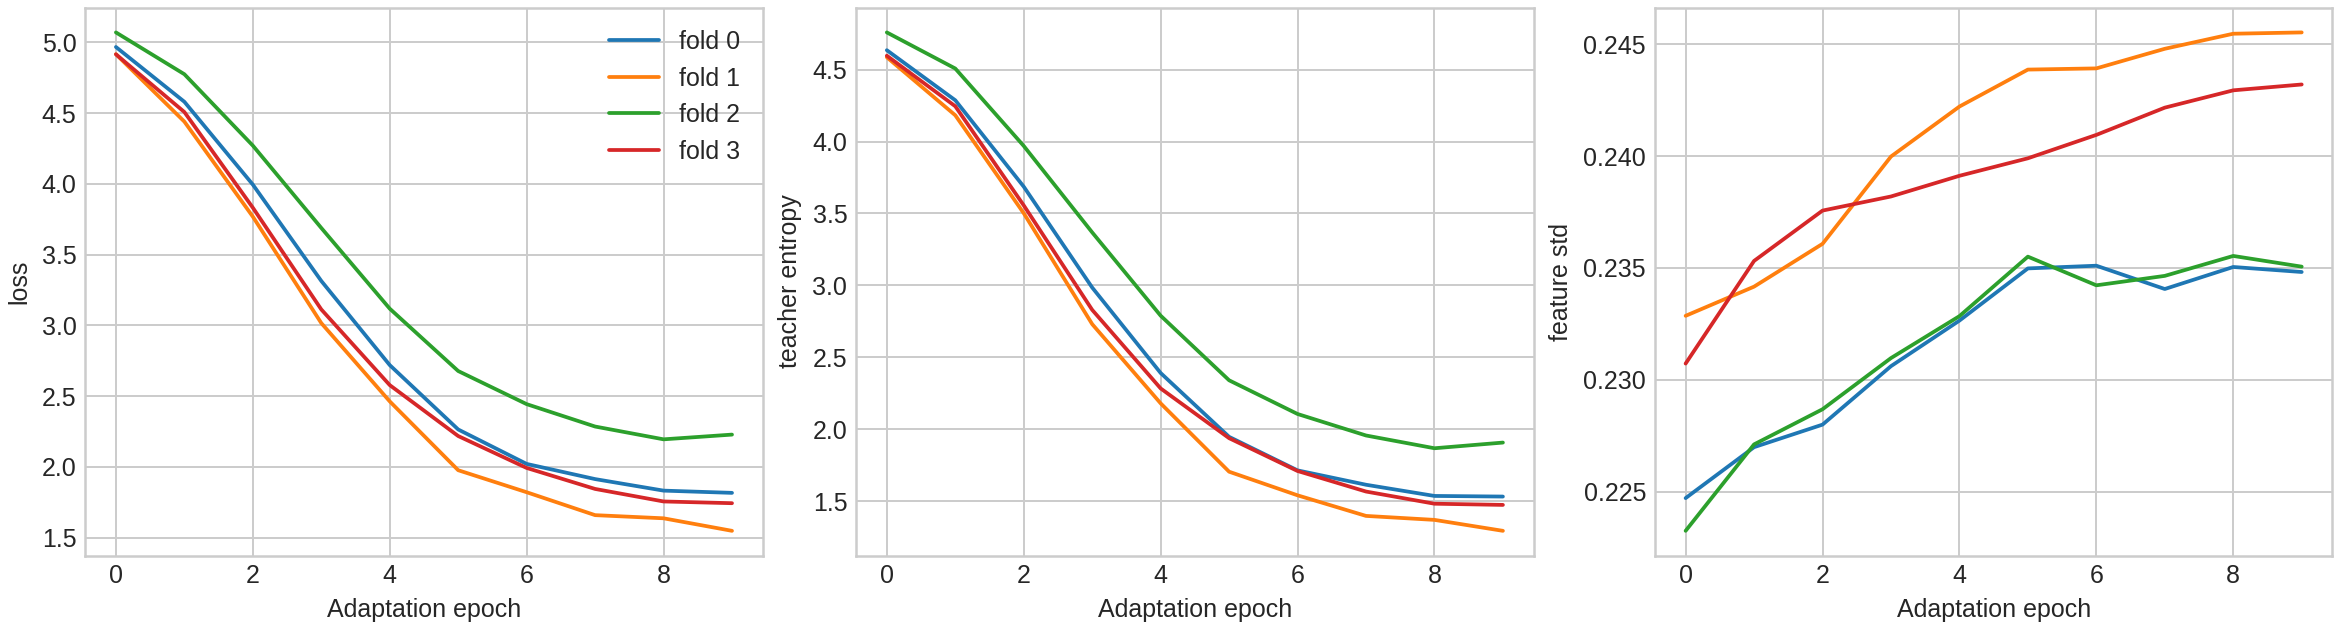

In [6]:
if not SMOKE:
    display(pd.read_csv(ROOT / 'results/adaptation_effects.csv'))
    display(pd.read_csv(ROOT / 'results/adaptation_compute.csv'))
    display(__import__('IPython').display.Image(filename=str(ROOT / 'results/adaptation_curves.png')))

## 7 · Did fine-tuning distort transferable features?

Centered linear CKA uses the **same held-out tile IDs** before and after tuning.
These tiles are correlated within soils. CKA and centered RankMe are descriptive
and do not select checkpoints. High CKA is not itself evidence of good transfer;
collapsed features have undefined CKA.

Ablations isolate CLS vs CLS+patch pooling, layer decay and color jitter.

,experiment,fold,cka,rankme_before,rankme_after,feature_std_before,feature_std_after,rows,unit
0,dinov3-lp,0,1.000000,77.455580,77.455580,0.224272,0.224272,128,"matched held-out physical tiles; descriptive, ..."
1,dinov3-lp,1,1.000000,76.213187,76.213187,0.212379,0.212379,128,"matched held-out physical tiles; descriptive, ..."
2,dinov3-lp,2,1.000000,69.766124,69.766124,0.230556,0.230556,116,"matched held-out physical tiles; descriptive, ..."
3,dinov3-lp,3,1.000000,82.578243,82.578243,0.216056,0.216056,136,"matched held-out physical tiles; descriptive, ..."
4,dinov3-lpft,0,0.999717,77.455580,77.487988,0.224272,0.225934,128,"matched held-out physical tiles; descriptive, ..."
5,dinov3-lpft,1,0.999783,76.213187,76.511548,0.212379,0.212714,128,"matched held-out physical tiles; descriptive, ..."
6,dinov3-lpft,2,0.999907,69.766124,69.846010,0.230556,0.231877,116,"matched held-out physical tiles; descriptive, ..."
7,dinov3-lpft,3,0.999918,82.578243,82.653666,0.216056,0.217372,136,"matched held-out physical tiles; descriptive, ..."
8,dinov3-full,0,0.995700,77.455580,77.408883,0.224272,0.231188,128,"matched held-out physical tiles; descriptive, ..."
9,dinov3-full,1,0.979900,76.213187,75.907996,0.212379,0.225006,128,"matched held-out physical tiles; descriptive, ..."


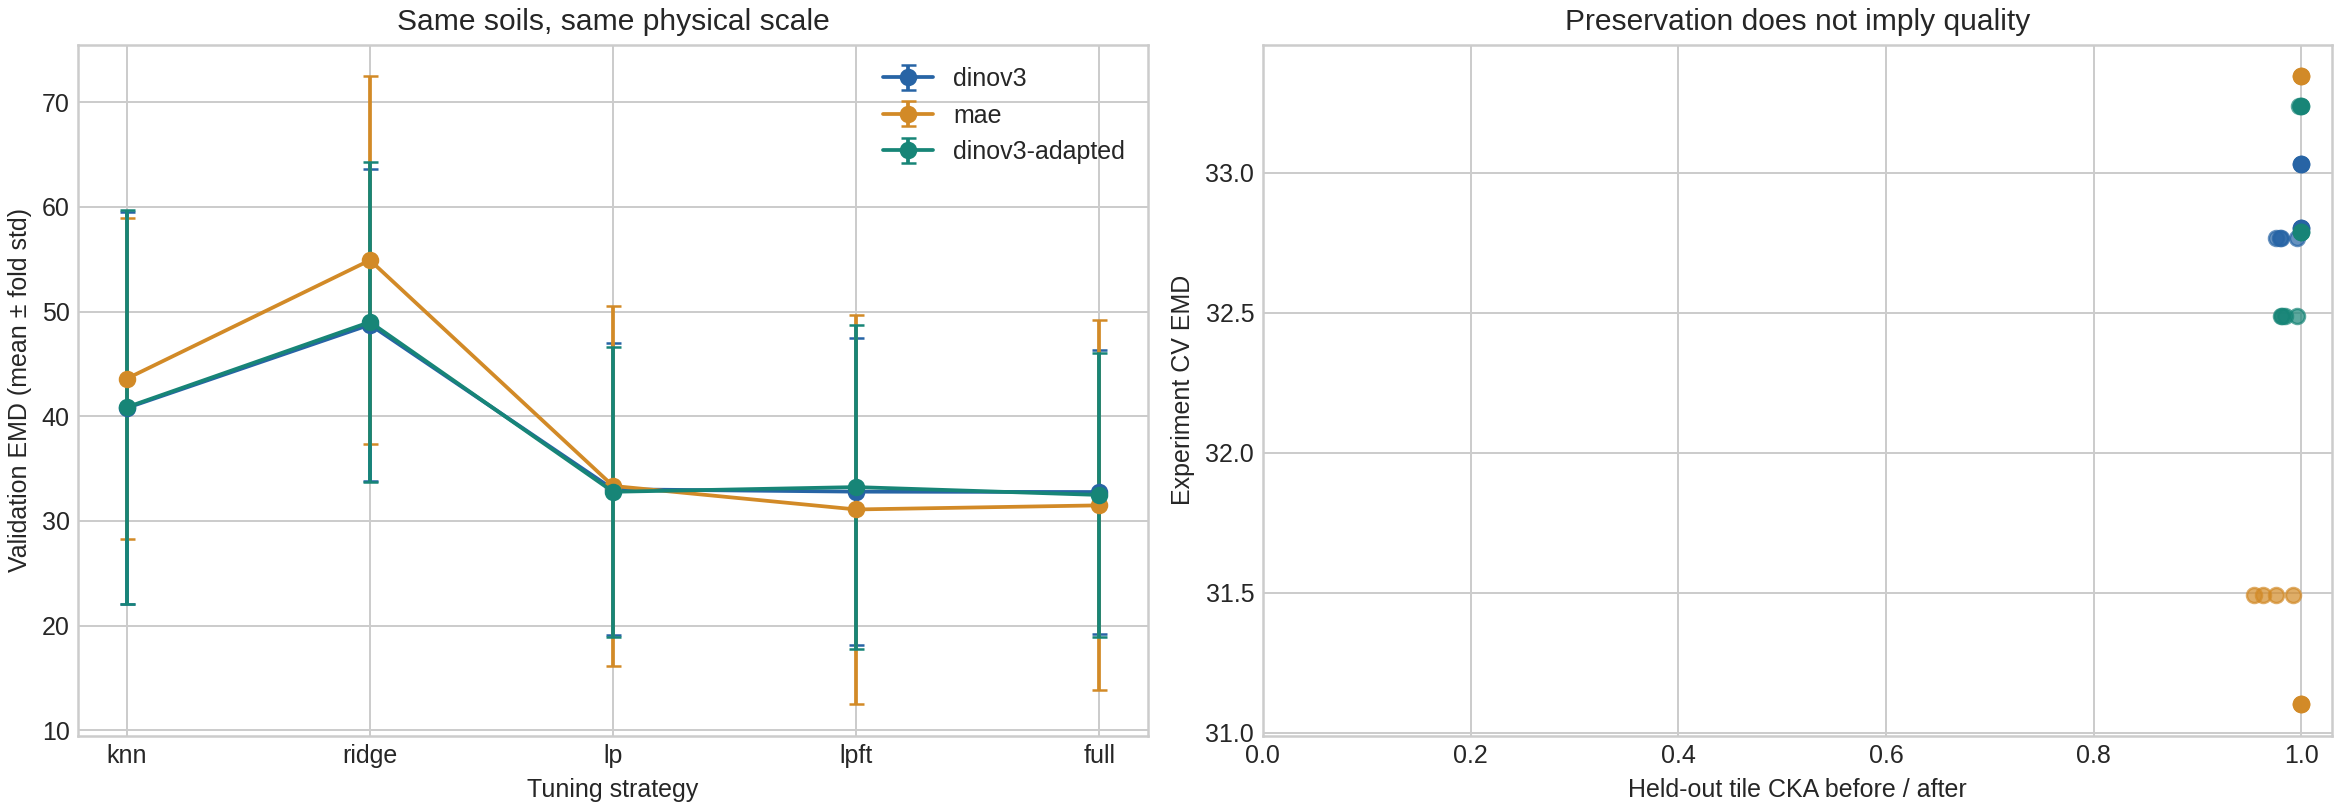

In [7]:
if not SMOKE:
    display(pd.read_csv(ROOT / 'results/representations.csv'))
    display(__import__('IPython').display.Image(filename=str(ROOT / 'results/transfer_comparison.png')))

## 8 · Reproduce a curve from photos + scale

Each recipe folder stores safe numerical regressors or neural weights and exact
preprocessing. `predict_fold` reconstructs the model without Hub access.
`predict_ensemble` requires one matching fold 0–3 for the same recipe and study.

```python
from soilcv.ssl.inference import predict_fold, predict_ensemble
# photos: sample_id, photo, absolute path, ppm_est, device
curve = predict_fold(recipe_folder, photos, cache_root, device='cuda:0', amp=True)
```

The complete source, lockfile, model revisions, fold IDs, OOF curves, run links,
compute records and SHA256 manifest are in the saved output directory.
LB entries remain empty until real submission receipts exist.

**AI disclosure.** Codex assisted with implementation and testing. Retain this
chat transcript and review the methods for the oral defence.

Sources: [DINOv3](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m) ·
[MAE](https://huggingface.co/facebook/vit-mae-base) ·
[DINO](https://arxiv.org/abs/2104.14294) · [CKA](https://arxiv.org/abs/1905.00414).